In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

TensorFlow version: 2.21.0
GPU available: True


In [ ]:
%pip install -q importlib_resources tensorflow-datasets

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds

(raw_train, raw_val), dataset_info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:90%]"],
    as_supervised=True,
    with_info=True,
    data_dir="/content/tensorflow_datasets"
)

print("Dataset loaded successfully!")
print("Classes:", dataset_info.features["label"].names)
print("Training samples:", len(list(raw_train.take(5))))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tensorflow_datasets/cats_vs_dogs/incomplete.SDWB33_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][…

Dataset cats_vs_dogs downloaded and prepared to /content/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset loaded successfully!
Classes: ['cat', 'dog']
Training samples: 5


In [ ]:
import tensorflow as tf

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

(raw_train, raw_val), dataset_info = tfds.load(
    "cats_vs_dogs",
    split=["train[:80%]", "train[80%:90%]"],
    as_supervised=True,
    with_info=True,
    data_dir="/content/tensorflow_datasets"
)

def preprocess_image(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

train_ds = (
    raw_train
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    raw_val
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

class_names = dataset_info.features["label"].names

print("Classes:", class_names)
print("Training and validation datasets are ready!")

Classes: ['cat', 'dog']
Training and validation datasets are ready!


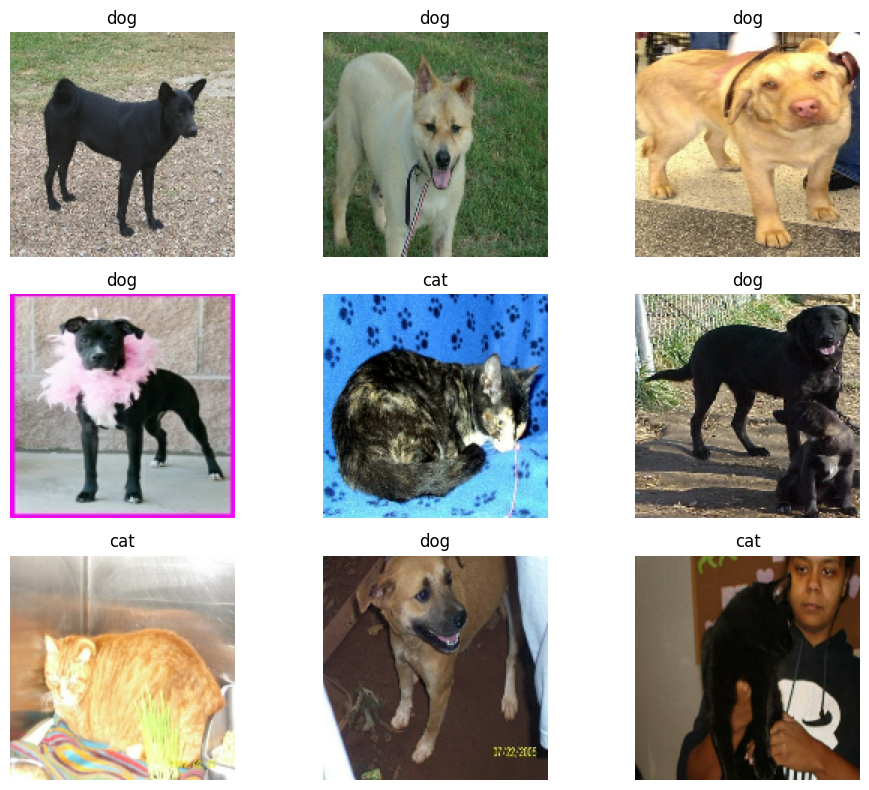

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images_batch, labels_batch in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images_batch[i].numpy().astype("uint8"))

        label_index = int(labels_batch[i].numpy())
        plt.title(class_names[label_index])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    layers.Rescaling(1.0 / 255),

    # Convolutional Layer 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolutional Layer 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 41s 54ms/step - accuracy: 0.6823 - loss: 0.5848 - val_accuracy: 0.7807 - val_loss: 0.4740
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 25s 41ms/step - accuracy: 0.7821 - loss: 0.4711 - val_accuracy: 0.8027 - val_loss: 0.4371
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 25s 41ms/step - accuracy: 0.8203 - loss: 0.4006 - val_accuracy: 0.8121 - val_loss: 0.4311
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 25s 41ms/step - accuracy: 0.8530 - loss: 0.3412 - val_accuracy: 0.8199 - val_loss: 0.3990
Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.8857 - loss: 0.2715 - val_accuracy: 0.8405 - val_loss: 0.3899
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9132 - loss: 0.2133 - val_accuracy: 0.8383 - val_loss: 0.4393
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 25s 40ms/step - accuracy: 0.9360 - loss: 0.1624 - val_accuracy: 0.8448 - val_loss: 0.4477
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 24s 40ms/step - accuracy: 0.9498 - loss: 0.1267 - 

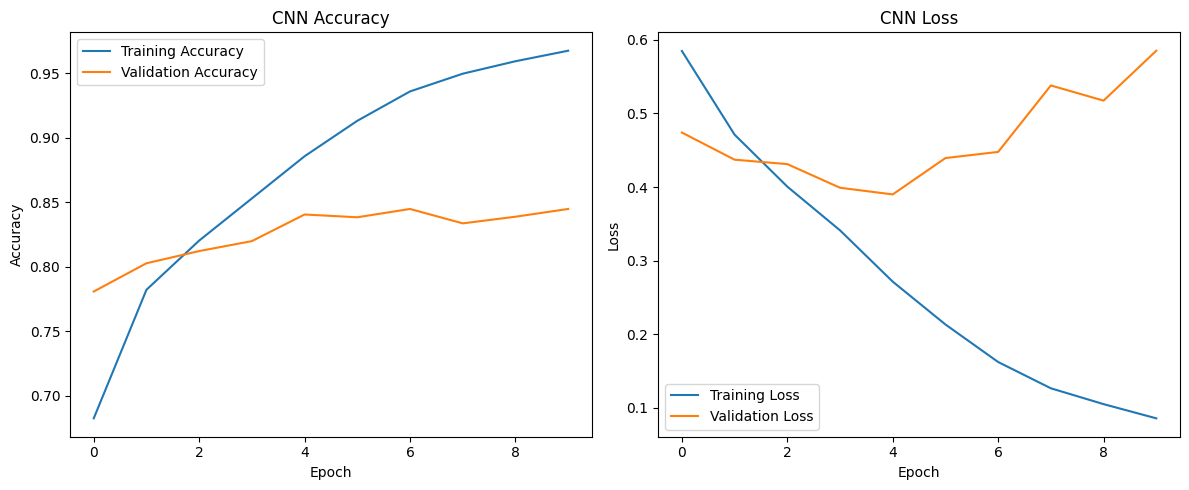

In [ ]:

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:

raw_test = tfds.load(
    "cats_vs_dogs",
    split="train[90%:]",
    as_supervised=True,
    data_dir="/content/tensorflow_datasets"
)

test_ds = (
    raw_test
    .map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

73/73 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.8487 - loss: 0.5630
Test Loss: 0.563
Test Accuracy: 84.87 %


Saving images (11).jpeg to images (11).jpeg


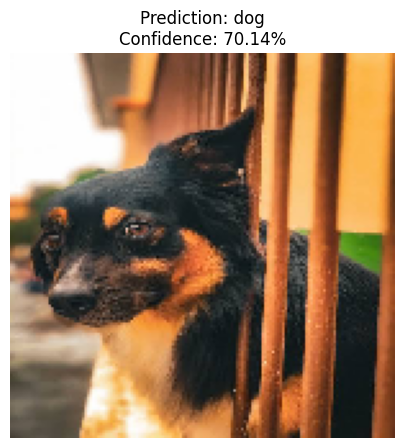

Predicted class: dog
Confidence: 70.14%


In [ ]:

from google.colab import files

uploaded = files.upload()

for filename in uploaded.keys():
    img = image.load_img(filename, target_size=IMG_SIZE)
    img_array = image.img_to_array(img)

    prediction = model.predict(
        np.expand_dims(img_array, axis=0),
        verbose=0
    )[0][0]

    if prediction >= 0.5:
        predicted_class = class_names[1]
        confidence = prediction
    else:
        predicted_class = class_names[0]
        confidence = 1 - prediction

    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

    print("Predicted class:", predicted_class)
    print("Confidence:", f"{confidence * 100:.2f}%")

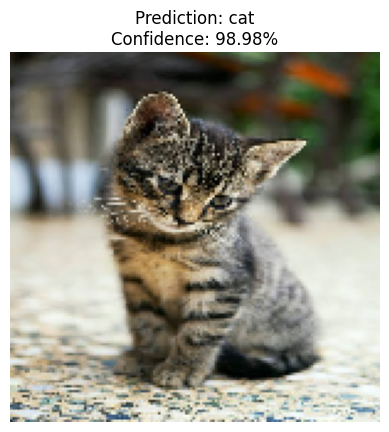

Predicted class: cat
Confidence: 98.98%


In [ ]:


from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

for filename in uploaded.keys():
    img = image.load_img(filename, target_size=IMG_SIZE)
    img_array = image.img_to_array(img)

    prediction = model.predict(
        np.expand_dims(img_array, axis=0),
        verbose=0
    )[0][0]

    if prediction >= 0.5:
        predicted_class = class_names[1]
        confidence = prediction
    else:
        predicted_class = class_names[0]
        confidence = 1 - prediction

    plt.imshow(img)
    plt.title(
        f"Prediction: {predicted_class}\n"
        f"Confidence: {confidence * 100:.2f}%"
    )
    plt.axis("off")
    plt.show()

    print("Predicted class:", predicted_class)
    print(f"Confidence: {confidence * 100:.2f}%")

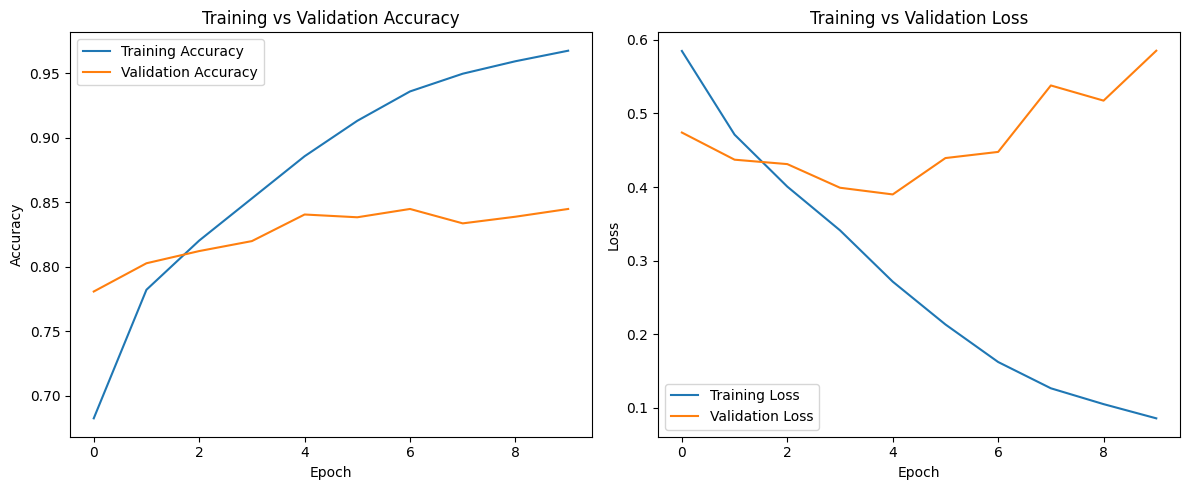

In [ ]:


import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

         cat     0.8984    0.7853    0.8381      1160
         dog     0.8102    0.9117    0.8579      1166

    accuracy                         0.8487      2326
   macro avg     0.8543    0.8485    0.8480      2326
weighted avg     0.8542    0.8487    0.8480      2326



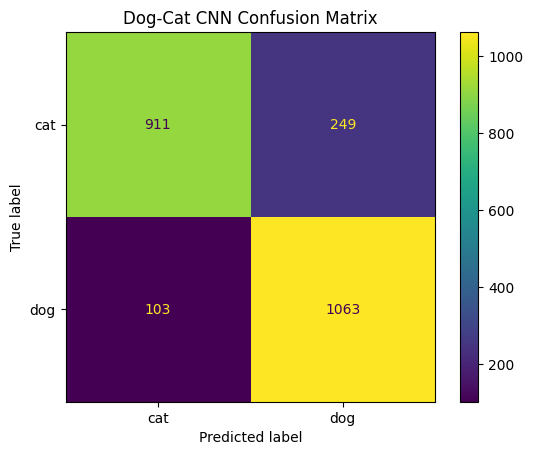

In [ ]:


from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

y_true = []
y_pred = []

for images_batch, labels_batch in test_ds:
    predictions = model.predict(images_batch, verbose=0)
    y_true.extend(labels_batch.numpy().astype(int))
    y_pred.extend((predictions.ravel() >= 0.5).astype(int))

print(classification_report(
    y_true, y_pred,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(values_format="d")
plt.title("Dog-Cat CNN Confusion Matrix")
plt.show()

In [ ]:

model.save("dog_cat_cnn.keras")
print("Model saved successfully!")

Model saved successfully!
